# R5 · Cross-platform search (Xenium ↔ Visium)

Fig 5. Two registered serial breast sections: Xenium tiles (≤ 2,000 cells each), with the same boxes laid over the
Visium spots. For each layout seed 0–4 and each direction, the index platform's tiles are indexed with Spindle-naive and
Spindle, and every tile of the other platform is a query. Spindle-naive is run with three platform corrections
(none, per niche, global shift); Spindle uses the global-shifted query. Readouts:
* tissue agreement r (query tumour fraction vs the mean of its top 10), the headline;
* co-located tile rank;
* Spindle NX5 / Overlap against Spindle-naive.

Also produced: the section maps, the platform-bias PCA and the example query (Fig 5E).
Definitions are in `experiments/common/cross_platform.py`.

* **Prerequisites:** the two cross-modal h5ads (`datasets.yaml`). This notebook does **not** need R0: it builds its own
  tiles (cached in `results/_cache/cross_modal/tiles2000.pkl`) and its own small indexes per seed.
* **Writes:** `results/cross_platform/` (see `manifest.json`); per-seed tables in `per_seed/`.
* **Skips** the tile cache and any seed whose per-seed tables exist (`FORCE = True` redoes them).
* **Runtime / memory:** about 2 min on one core (cluster, 31 Oct 2026); peak about 1.7 GB.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import cross_platform as cp
import data
import results_io as rio

FORCE = False
TOPIC = "cross_platform"
OUT = rio.topic(TOPIC)
PER_SEED = OUT / "per_seed"
PER_SEED.mkdir(exist_ok=True)
pd.set_option("display.width", 200)
print(data.stamp())

{'tag': 'method-v2', 'describe': 'method-v2-dirty', 'commit': '8040f91'}


## Tiles and shrunk covariances of both platforms (cached, seed-independent)

In [2]:
S = cp.setup()
print(f"{len(S['genes'])} shared genes; {len(S['tiles']['Xenium'])} Xenium tiles, {len(S['tiles']['Visium'])} Visium tiles; "
      f"cells/spots {S['n_obs']}")

/home/NAShome/ghoss18/spindle_dev/src/spindle_dev/preprocessing.py:162: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = sc.read_h5ad(path)
/home/NAShome/ghoss18/spindle_dev/src/spindle_dev/preprocessing.py:164: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  adata = adata[adata.obs.loc[adata.obs.Cluster != "Unlabeled"].index, :].copy()
[2026-10-31 21:58:42,099] INFO spindle_dev.preprocessing: build_quadtree_tiles: dropping 1 low-density tile(s) (234 spots)


tiles2000: 307 genes, 165 Xenium / 156 Visium tiles
307 shared genes; 165 Xenium tiles, 156 Visium tiles; cells/spots {'Xenium': 137448, 'Visium': 3907}


## Search, per layout seed (both directions)

In [3]:
PARTS = {"per_query": "", "top10": "_top10", "spindle": "_spindle", "index": "_index"}
DESC = {"per_query": "per (method, direction, query): query / top-10 tumour fraction, random MAE, co-located rank, hit@1/5/10",
        "top10": "the top 10 index tiles of every (method, direction, query) with their d_B",
        "spindle": "Spindle (g = 0.25, global shift) against naive_global per query: NX5, Overlap, tiles returned, work",
        "index": "per direction: index sizes, niches, blocks, bytes of Spindle-naive and Spindle"}
for seed in data.SEEDS:
    files = {k: PER_SEED / f"seed{seed}{suf}.csv" for k, suf in PARTS.items()}
    if not FORCE and all(f.exists() for f in files.values()):
        print(f"seed {seed}: exists, skipped")
    else:
        res = cp.search(S, seed)
        for k, df in res.items():
            rio.write_csv(df, TOPIC, f"per_seed/seed{seed}{PARTS[k]}.csv", f"seed {seed}: {DESC[k]}")
    for k, f in files.items():
        rio.register(TOPIC, f, f"seed {seed}: {DESC[k]}")

def load(part):
    df = pd.concat([pd.read_csv(PER_SEED / f"seed{s}{PARTS[part]}.csv") for s in data.SEEDS], ignore_index=True)
    assert set(df["tag"]) == {data.TAG}, set(df["tag"])
    return df

/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
[2026-10-31 21:58:58,611] INFO spindle_dev.layout: Leiden resolution 0.20: 2 niches, sizes [91, 65]
[2026-10-31 21:58:58,820] INFO spindle_dev.layout: Niche 0: 16 blocks
[2026-10-31 21:58:58,889] INFO spindle_dev.layout: Niche 1: 17 blocks
[2026-10-31 21:58:59,064] INFO spindle_dev.spindle: Niche 0: 91 tiles, 16 layers, 132 nodes, 0.0s
[2026-10-31 21:58:59,082] INFO spindle_dev.spindle: Niche 1: 65 tiles, 17 layers, 104 nodes, 0.0s


seed 0 x2v: N = 156, 2 niches; tissue r {'naive_global': 0.888, 'naive_none': 0.157, 'naive_per_niche': 0.847}; spindle NX5 22.4 %, overlap 0.39


/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
[2026-10-31 21:59:03,700] INFO spindle_dev.layout: Leiden resolution 0.20: 3 niches, sizes [84, 60, 21]
[2026-10-31 21:59:03,917] INFO spindle_dev.layout: Niche 0: 16 blocks
[2026-10-31 21:59:03,969] INFO spindle_dev.layout: Niche 1: 15 blocks
[2026-10-31 21:59:04,020] INFO spindle_dev.layout: Niche 2: 15 blocks
[2026-10-31 21:59:04,213] INFO spindle_dev.spindle: Niche 0: 84 tiles, 16 layers, 110 nodes, 0.0s
[2026-10-31 21:59:04,229] INFO spindle_dev.spindle: Niche 1: 60 tiles, 15 layers, 87 nodes, 0.0s
[2026-10-31 21:59:04,233] INFO spindle_dev.spindle: Niche 2: 21 tiles, 15 layers, 30 nodes, 0.0s


seed 0 v2x: N = 165, 3 niches; tissue r {'naive_global': 0.844, 'naive_none': 0.777, 'naive_per_niche': 0.598}; spindle NX5 11.1 %, overlap 0.60
check: self rank 1 for 1.000 of tiles, max self d 0.0e+00; global shift onto itself: max |d - d_none| = 2.9e-11
wrote results/cross_platform/per_seed/seed0.csv: 963 rows
wrote results/cross_platform/per_seed/seed0_top10.csv: 9630 rows
wrote results/cross_platform/per_seed/seed0_spindle.csv: 321 rows
wrote results/cross_platform/per_seed/seed0_index.csv: 2 rows


/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
[2026-10-31 21:59:13,249] INFO spindle_dev.layout: Leiden resolution 0.20: 2 niches, sizes [91, 65]
[2026-10-31 21:59:13,453] INFO spindle_dev.layout: Niche 0: 17 blocks
[2026-10-31 21:59:13,520] INFO spindle_dev.layout: Niche 1: 17 blocks
[2026-10-31 21:59:13,693] INFO spindle_dev.spindle: Niche 0: 91 tiles, 17 layers, 152 nodes, 0.0s
[2026-10-31 21:59:13,711] INFO spindle_dev.spindle: Niche 1: 65 tiles, 17 layers, 73 nodes, 0.0s


seed 1 x2v: N = 156, 2 niches; tissue r {'naive_global': 0.896, 'naive_none': 0.156, 'naive_per_niche': 0.734}; spindle NX5 14.2 %, overlap 0.51


... (10 outputs left out)

/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
[2026-10-31 21:59:44,962] INFO spindle_dev.layout: Leiden resolution 0.20: 2 niches, sizes [86, 70]
[2026-10-31 21:59:45,166] INFO spindle_dev.layout: Niche 0: 17 blocks
[2026-10-31 21:59:45,235] INFO spindle_dev.layout: Niche 1: 17 blocks
[2026-10-31 21:59:45,406] INFO spindle_dev.spindle: Niche 0: 86 tiles, 17 layers, 148 nodes, 0.0s
[2026-10-31 21:59:45,425] INFO spindle_dev.spindle: Niche 1: 70 tiles, 17 layers, 78 nodes, 0.0s


seed 4 x2v: N = 156, 2 niches; tissue r {'naive_global': 0.885, 'naive_none': 0.157, 'naive_per_niche': 0.78}; spindle NX5 15.6 %, overlap 0.49


/home/NAShome/ghoss18/miniforge3/envs/spindle_env/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
[2026-10-31 21:59:49,932] INFO spindle_dev.layout: Leiden resolution 0.20: 3 niches, sizes [84, 48, 33]
[2026-10-31 21:59:50,146] INFO spindle_dev.layout: Niche 0: 16 blocks
[2026-10-31 21:59:50,193] INFO spindle_dev.layout: Niche 1: 13 blocks
[2026-10-31 21:59:50,256] INFO spindle_dev.layout: Niche 2: 18 blocks
[2026-10-31 21:59:50,451] INFO spindle_dev.spindle: Niche 0: 84 tiles, 16 layers, 110 nodes, 0.0s
[2026-10-31 21:59:50,463] INFO spindle_dev.spindle: Niche 1: 48 tiles, 13 layers, 41 nodes, 0.0s
[2026-10-31 21:59:50,469] INFO spindle_dev.spindle: Niche 2: 33 tiles, 18 layers, 62 nodes, 0.0s


seed 4 v2x: N = 165, 3 niches; tissue r {'naive_global': 0.844, 'naive_none': 0.781, 'naive_per_niche': 0.784}; spindle NX5 11.3 %, overlap 0.70
wrote results/cross_platform/per_seed/seed4.csv: 963 rows
wrote results/cross_platform/per_seed/seed4_top10.csv: 9630 rows
wrote results/cross_platform/per_seed/seed4_spindle.csv: 321 rows
wrote results/cross_platform/per_seed/seed4_index.csv: 2 rows


## Section maps, platform-bias PCA, example query

In [4]:
tiles, arrays = cp.maps(S)
rio.write_csv(tiles, TOPIC, "tiles.csv", "both platforms' tiles: box, cells / spots, coarse-class composition, "
              "tumour fraction, co-located Xenium tile")
np.savez_compressed(OUT / "cells.npz", **arrays)
rio.register(TOPIC, OUT / "cells.npz", "every Xenium cell and Visium spot: x, y, coarse class index (classes)")

proj, summ = cp.bias_pca(S)
rio.write_csv(proj, TOPIC, "bias_pca.csv", "PCA (5 PCs, fit on the index tiles) of the whole-matrix logs; query tiles "
              "before / after the global shift, per direction")
rio.write_csv(summ, TOPIC, "bias_pca_summary.csv", "per direction and state: platform silhouette, centroid gap, "
              "PC1-2 variance")
display(summ.round(3))

top10 = {s: pd.read_csv(PER_SEED / f"seed{s}_top10.csv") for s in data.SEEDS}
ex = cp.example(S, top10)
rio.write_csv(ex, TOPIC, "example.csv", "Fig 5E example (seed 0, Visium query, naive_global): its top 5 Xenium tiles, "
              "focal-class shares, co-located rank, top 5 in seeds 1-4, base rate")
del top10
display(ex)

wrote results/cross_platform/tiles.csv: 321 rows
wrote results/cross_platform/bias_pca.csv: 963 rows
wrote results/cross_platform/bias_pca_summary.csv: 4 rows


,direction,corrected,silhouette,centroid_gap,pc12_var,tag
0,x2v,False,0.501,2.254,0.811,method-v2
1,x2v,True,0.078,0.000,0.811,method-v2
2,v2x,False,0.501,2.254,0.449,method-v2
3,v2x,True,0.030,0.000,0.449,method-v2


example: Visium query 60 (12 candidates of 46 focal-rich queries), Immune 0.87; top-5 Xenium Immune 0.49-0.69 (mean 0.59; section 0.218); co-located tile 63 at rank 5; base rate 0.83; seeds 1-4: ['92 133 160 147 63', '92 133 160 147 63', '92 133 160 147 63', '92 133 160 147 63']
wrote results/cross_platform/example.csv: 5 rows


,rank,index_tile,matched,hit_share,query,focal_class,query_share,matched_tile,section_share,n_rich,n_candidates,rich_above_section,top5_seed1,top5_seed2,top5_seed3,top5_seed4,tag
0,1,92,False,0.528099,60,Immune,0.866667,63,0.218301,46,12,0.826087,92 133 160 147 63,92 133 160 147 63,92 133 160 147 63,92 133 160 147 63,method-v2
1,2,133,False,0.492099,60,Immune,0.866667,63,0.218301,46,12,0.826087,92 133 160 147 63,92 133 160 147 63,92 133 160 147 63,92 133 160 147 63,method-v2
2,3,160,False,0.628571,60,Immune,0.866667,63,0.218301,46,12,0.826087,92 133 160 147 63,92 133 160 147 63,92 133 160 147 63,92 133 160 147 63,method-v2
3,4,147,False,0.601064,60,Immune,0.866667,63,0.218301,46,12,0.826087,92 133 160 147 63,92 133 160 147 63,92 133 160 147 63,92 133 160 147 63,method-v2
4,5,63,True,0.689189,60,Immune,0.866667,63,0.218301,46,12,0.826087,92 133 160 147 63,92 133 160 147 63,92 133 160 147 63,92 133 160 147 63,method-v2


## Summaries

In [5]:
pq = load("per_query")
ts = cp.tissue_seeds(pq)
rio.write_csv(ts, TOPIC, "tissue_seeds.csv", "per (direction, method, seed): tissue agreement r, MAE (top 10 / random), "
              "hit@1/5/10, median co-located rank, N")
tissue = cp.seed_stats(ts, ["direction", "method"])
rio.write_csv(tissue, TOPIC, "tissue.csv", "per (direction, method): mean and s.d. over seeds 0-4 of tissue_seeds.csv")
s0 = pq[(pq.seed == data.EXAMPLE_SEED) & (pq.method == "naive_global")]
rio.write_csv(s0[["direction", "query", "query_tumour", "hits_tumour", "tag"]], TOPIC, "tissue_seed0.csv",
              "seed 0, naive_global: per query its tumour fraction and its top 10's mean (Fig 5C)")
spindle = cp.spindle_summary(load("spindle"))
rio.write_csv(spindle, TOPIC, "spindle.csv", "per direction: Spindle against naive_global (NX5, Overlap, tiles "
              "returned, work), mean over queries per seed, then mean and s.d. over seeds")
index = cp.index_summary(load("index"))
rio.write_csv(index, TOPIC, "index.csv", "per direction: N, query tiles, p, niches / blocks (min-max over seeds), "
              "Spindle-naive and Spindle MB")
display(tissue[["direction", "method", "tissue_r_mean", "tissue_r_std", "mae_mean", "mae_random_mean",
                "hit5_mean", "hit5_random_mean"]].round(3))
display(spindle.round(3))
display(index.round(2))

wrote results/cross_platform/tissue_seeds.csv: 30 rows
wrote results/cross_platform/tissue.csv: 6 rows
wrote results/cross_platform/tissue_seed0.csv: 321 rows
wrote results/cross_platform/spindle.csv: 2 rows
wrote results/cross_platform/index.csv: 2 rows


,direction,method,tissue_r_mean,tissue_r_std,mae_mean,mae_random_mean,hit5_mean,hit5_random_mean
0,v2x,naive_global,0.844,0.000,0.284,0.424,0.186,0.030
1,v2x,naive_none,0.780,0.002,0.342,0.424,0.121,0.030
2,v2x,naive_per_niche,0.747,0.084,0.263,0.424,0.168,0.030
3,x2v,naive_global,0.891,0.004,0.176,0.424,0.172,0.032
4,x2v,naive_none,0.155,0.002,0.379,0.424,0.060,0.032
5,x2v,naive_per_niche,0.785,0.040,0.327,0.424,0.162,0.032


,direction,NX5_mean,NX5_std,overlap5_mean,overlap5_std,n_found_mean,n_found_std,work_mean,work_std,n_seeds,tag
0,v2x,0.113,0.001,0.681,0.045,28.555,1.138,151.824,0.869,5,method-v2
1,x2v,0.158,0.038,0.488,0.055,39.328,4.056,111.932,8.612,5,method-v2


,direction,N,n_query,p,niches_min,niches_max,blocks_min,blocks_max,naive_mb,spindle_mb,tag
0,v2x,165,156,307,3,3,46,47,2.57,0.29,method-v2
1,x2v,156,165,307,2,2,33,35,2.15,0.25,method-v2


## Summary plots (not saved)

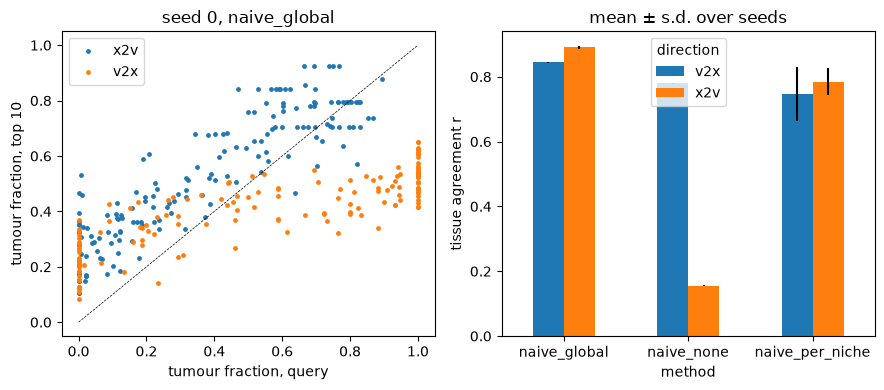

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for d, c in (("x2v", "tab:blue"), ("v2x", "tab:orange")):
    g = s0[s0.direction == d]
    axs[0].scatter(g.query_tumour, g.hits_tumour, s=6, c=c, label=d)
axs[0].plot([0, 1], [0, 1], "k--", lw=0.5)
axs[0].set(xlabel="tumour fraction, query", ylabel="tumour fraction, top 10", title="seed 0, naive_global")
axs[0].legend()
t = tissue.pivot(index="method", columns="direction", values="tissue_r_mean")
t.plot.bar(ax=axs[1], yerr=tissue.pivot(index="method", columns="direction", values="tissue_r_std"), rot=0)
axs[1].set(ylabel="tissue agreement r", title="mean ± s.d. over seeds")
plt.tight_layout()
plt.show()

In [7]:
rio.write_manifest(TOPIC, "R5_cross_platform.ipynb", inputs=["datasets.yaml: cross_modal_xenium, cross_modal_visium",
                                                            "results/_cache/cross_modal/tiles2000.pkl"])

wrote results/cross_platform/manifest.json: 30 files; peak memory 1.66 GB


{'topic': 'cross_platform',
 'notebook': 'R5_cross_platform.ipynb',
 'date': '2026-10-31 21:59',
 'tag': 'method-v2',
 'describe': 'method-v2-dirty',
 'commit': '8040f91',
 'inputs': ['datasets.yaml: cross_modal_xenium, cross_modal_visium',
  'results/_cache/cross_modal/tiles2000.pkl'],
 'peak_rss_gb': 1.66,
 'notes': '',
 'files': {'bias_pca.csv': {'description': 'PCA (5 PCs, fit on the index tiles) of the whole-matrix logs; query tiles before / after the global shift, per direction',
   'rows': 963,
   'bytes': 123106},
  'bias_pca_summary.csv': {'description': 'per direction and state: platform silhouette, centroid gap, PC1-2 variance',
   'rows': 4,
   'bytes': 372},
  'cells.npz': {'description': 'every Xenium cell and Visium spot: x, y, coarse class index (classes)',
   'rows': None,
   'bytes': 1007185},
  'example.csv': {'description': 'Fig 5E example (seed 0, Visium query, naive_global): its top 5 Xenium tiles, focal-class shares, co-located rank, top 5 in seeds 1-4, base rate